## 6-4_Assessing_cluster_correctness

In [1]:
## 1. Generate synthetic data with ground-truth cluster labels.

from sklearn import datasets
from sklearn import cluster

blobs, ground_truth = datasets.make_blobs(1000, centers=3,cluster_std=1.75)

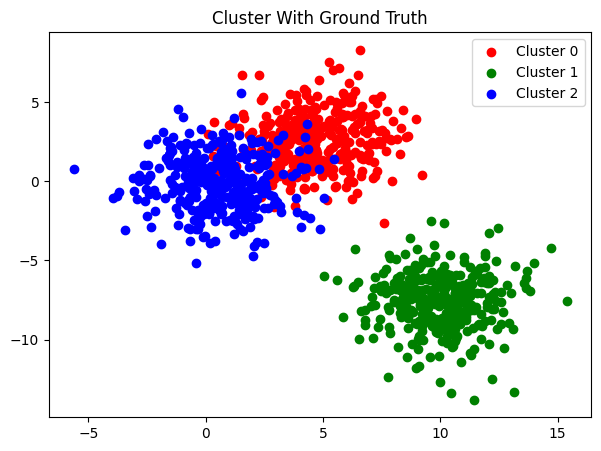

In [2]:
## 2. Visualize the ground-truth clusters.

from sklearn import datasets
from sklearn import cluster

%matplotlib inline
import matplotlib.pyplot as plt

f, ax = plt.subplots(figsize=(7, 5))
colors = ['r', 'g', 'b']
for i in range(3):
     p = blobs[ground_truth == i]
     ax.scatter(p[:,0], p[:,1], c=colors[i],
     label="Cluster {}".format(i))
ax.set_title("Cluster With Ground Truth")
ax.legend()

In [3]:
## 3. Train the K-Means clustering model.

kmeans = cluster.KMeans(n_clusters=3)
kmeans.fit(blobs)

,"n_clusters n_clusters: int, default=8The number of clusters to form as well as the number ofcentroids to generate.For an example of how to choose an optimal value for `n_clusters` refer to:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_silhouette_analysis.py`.",3
,"init init: {'k-means++', 'random'}, callable or array-like of shape (n_clusters, n_features), default='k-means++'Method for initialization:* 'k-means++' : selects initial cluster centroids using sampling based on an empirical probability distribution of the points' contribution to the overall inertia. This technique speeds up convergence. The algorithm implemented is ""greedy k-means++"". It differs from the vanilla k-means++ by making several trials at each sampling step and choosing the best centroid among them.* 'random': choose `n_clusters` observations (rows) at random from data for the initial centroids.* If an array is passed, it should be of shape (n_clusters, n_features) and gives the initial centers.* If a callable is passed, it should take arguments X, n_clusters and a random state and return an initialization.For an example of how to use the different `init` strategies, see:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_digits.py`.For an evaluation of the impact of initialization, see the example:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.",'k-means++'
,"n_init n_init: 'auto' or int, default='auto'Number of times the k-means algorithm is run with different centroidseeds. The final results is the best output of `n_init` consecutive runsin terms of inertia. Several runs are recommended for sparsehigh-dimensional problems (see :ref:`kmeans_sparse_high_dim`).When `n_init='auto'`, the number of runs depends on the value of init:10 if using `init='random'` or `init` is a callable;1 if using `init='k-means++'` or `init` is an array-like... versionadded:: 1.2 Added 'auto' option for `n_init`... versionchanged:: 1.4 Default value for `n_init` changed to `'auto'`.",'auto'
,"max_iter max_iter: int, default=300Maximum number of iterations of the k-means algorithm for asingle run.",300
,"tol tol: float, default=1e-4Relative tolerance with regards to Frobenius norm of the differencein the cluster centers of two consecutive iterations to declareconvergence.",0.0001
,"verbose verbose: int, default=0Verbosity mode.",0
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for centroid initialization. Usean int to make the randomness deterministic.See :term:`Glossary `.",None
,"copy_x copy_x: bool, default=TrueWhen pre-computing distances it is more numerically accurate to centerthe data first. If copy_x is True (default), then the original data isnot modified. If False, the original data is modified, and put backbefore the function returns, but small numerical differences may beintroduced by subtracting and then adding the data mean. Note that ifthe original data is not C-contiguous, a copy will be made even ifcopy_x is False. If the original data is sparse, but not in CSR format,a copy will be made even if copy_x is False.",True
,"algorithm algorithm: {""lloyd"", ""elkan""}, default=""lloyd""K-means algorithm to use. The classical EM-style algorithm is `""lloyd""`.The `""elkan""` variation can be more efficient on some datasets withwell-defined clusters, by using the triangle inequality. However it'smore memory intensive due to the allocation of an extra array of shape`(n_samples, n_clusters)`... versionchanged:: 0.18 Added Elkan algorithm.. versionchanged:: 1.1 Renamed ""full"" to ""lloyd"", and deprecated ""auto"" and ""full"". Changed ""auto"" to use ""lloyd"" instead of ""elkan"".",'lloyd'


In [4]:
## 4. Inspect the coordinates of the cluster centers.

kmeans.cluster_centers_

array([[ 0.48518928, -0.09923955],
       [ 9.9911522 , -7.5662093 ],
       [ 4.85736057,  2.73000713]])

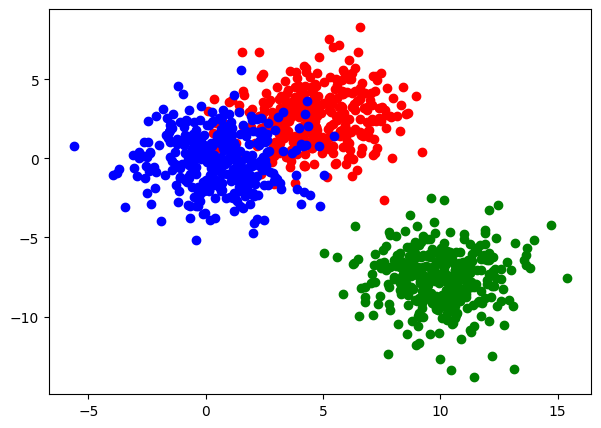

In [6]:
## 5. Visualize the original clusters again.

f, ax = plt.subplots(figsize=(7, 5))
colors = ['r', 'g', 'b']
for i in range(3): 
     p = blobs[ground_truth == i]
     ax.scatter(p[:,0], p[:,1], c=colors[i], label="Cluster {}".format(i))

In [8]:
## 6. Compare predicted cluster labels with ground-truth labels.

for i in range(3):
     print(((kmeans.labels_ == ground_truth)[ground_truth == i]).astype(int).mean())

0.08383233532934131
1.0
0.07507507507507508


In [9]:
## 7. Swap ground-truth labels 1 and 2.

#Not necessary here:

new_ground_truth = ground_truth.copy()
new_ground_truth[ground_truth == 1] = 2
new_ground_truth[ground_truth == 2] = 1

In [10]:
## 8. Calculate normalized mutual information between true and predicted labels.

from sklearn import metrics
metrics.normalized_mutual_info_score(ground_truth, kmeans.labels_)

0.8254988205004028

In [11]:
## 9. Calculate normalized mutual information for identical labels.

metrics.normalized_mutual_info_score(ground_truth, ground_truth)

1.0

In [12]:
## 10. Calculate mutual information between true and predicted labels.

metrics.mutual_info_score(ground_truth, kmeans.labels_)

0.9068911677183352

In [13]:
## 11. Inspect the K-Means inertia.

kmeans.inertia_

5604.296867288229